<a href="https://colab.research.google.com/github/tithisorker187/Biostatistics-lab/blob/main/SP_TithiRiya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
df=pd.read_csv("/content/Statistical_project_clean_datasets (copy)no_missing_value.csv")
df.head()


,id,age,sex,union,village,under5,num_under5,literacy,occupation,hh_size,...,hygiene1,hygiene2,hygiene3,hygiene4,hygiene5,diarrhea,ors,treatment,duration,recovered
0,1,24,2,1,1,1,1,1,1,4,...,3,5,5,3,4,0,NaN,NaN,NaN,NaN
1,2,40,2,1,2,1,1,1,1,6,...,3,3,2,2,2,1,1.0,1.0,3.0,1.0
2,3,45,2,1,2,1,1,0,1,5,...,2,4,3,3,2,0,NaN,NaN,NaN,NaN
3,4,32,2,1,2,1,1,1,2,5,...,3,4,4,3,4,0,NaN,NaN,NaN,NaN
4,5,23,2,1,2,1,1,0,1,5,...,3,5,3,3,2,1,1.0,0.0,3.0,1.0


In [ ]:
df.columns.tolist()

['id',
 'age',
 'sex',
 'union',
 'village',
 'under5',
 'num_under5',
 'literacy',
 'occupation',
 'hh_size',
 'house_type',
 'electricity',
 'mobile',
 'tv',
 'refrigerator',
 'motorcycle_boat',
 'agri_land',
 'water_source',
 'water_treatment',
 'toilet_type',
 'toilet_shared',
 'handwash_facility',
 'hygiene1',
 'hygiene2',
 'hygiene3',
 'hygiene4',
 'hygiene5',
 'diarrhea',
 'ors',
 'treatment',
 'duration',
 'recovered']

In [ ]:
df.columns = df.columns.str.strip()
df.info()
df.dtypes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 300 non-null    int64  
 1   age                300 non-null    int64  
 2   sex                300 non-null    int64  
 3   union              300 non-null    int64  
 4   village            300 non-null    int64  
 5   under5             300 non-null    int64  
 6   num_under5         300 non-null    int64  
 7   literacy           300 non-null    int64  
 8   occupation         300 non-null    int64  
 9   hh_size            300 non-null    int64  
 10  house_type         300 non-null    int64  
 11  electricity        300 non-null    int64  
 12  mobile             300 non-null    int64  
 13  tv                 300 non-null    int64  
 14  refrigerator       300 non-null    int64  
 15  motorcycle_boat    300 non-null    int64  
 16  agri_land          300 non

,0
id,int64
age,int64
sex,int64
union,int64
village,int64
under5,int64
num_under5,int64
literacy,int64
occupation,int64
hh_size,int64


In [ ]:
#check duplicate
df['id'].duplicated().sum()
df.duplicated().sum()
df[df.duplicated(keep=False)]


,id,age,sex,union,village,under5,num_under5,literacy,occupation,hh_size,...,hygiene1,hygiene2,hygiene3,hygiene4,hygiene5,diarrhea,ors,treatment,duration,recovered


In [ ]:
#Basic Numerical Summary
df.describe()

,id,age,sex,union,village,under5,num_under5,literacy,occupation,hh_size,...,hygiene1,hygiene2,hygiene3,hygiene4,hygiene5,diarrhea,ors,treatment,duration,recovered
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.0,300.000000,300.000000,300.000000,300.000000,...,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,67.000000,67.000000,66.000000,67.000000
mean,150.500000,27.083333,1.966667,2.000000,3.500000,1.0,1.273333,0.813333,1.186667,5.150000,...,2.433333,4.113333,3.656667,3.306667,3.150000,0.223333,0.791045,0.492537,1.757576,0.791045
std,86.746758,8.173887,0.179805,0.817861,1.710679,0.0,0.522365,0.390295,0.766233,1.771429,...,1.040431,1.053973,0.917384,0.921295,0.943646,0.417176,0.409631,0.503718,0.823886,0.409631
min,1.000000,15.000000,1.000000,1.000000,1.000000,1.0,1.000000,0.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,75.750000,21.000000,2.000000,1.000000,2.000000,1.0,1.000000,1.000000,1.000000,4.000000,...,2.000000,4.000000,3.000000,3.000000,3.000000,0.000000,1.000000,0.000000,1.000000,1.000000
50%,150.500000,25.000000,2.000000,2.000000,3.500000,1.0,1.000000,1.000000,1.000000,5.000000,...,2.000000,4.000000,4.000000,3.000000,3.000000,0.000000,1.000000,0.000000,2.000000,1.000000
75%,225.250000,30.000000,2.000000,3.000000,5.000000,1.0,2.000000,1.000000,1.000000,6.000000,...,3.000000,5.000000,4.000000,4.000000,4.000000,0.000000,1.000000,1.000000,2.000000,1.000000
max,300.000000,70.000000,2.000000,3.000000,6.000000,1.0,6.000000,1.000000,6.000000,11.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,1.000000,1.000000,1.000000,3.000000,1.000000


In [ ]:
#Check Missing values
df.isnull().sum()
(df.isnull().sum() / len(df) * 100).round(2)
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': (df.isnull().sum() / len(df) * 100).round(2)
})

missing

,Missing_Count,Missing_Percent
id,0,0.00
age,0,0.00
sex,0,0.00
union,0,0.00
village,0,0.00
under5,0,0.00
num_under5,0,0.00
literacy,0,0.00
occupation,0,0.00
hh_size,0,0.00


In [ ]:
missing[missing['Missing_Count'] > 0]
df.isnull().sum().sort_values(ascending=False)
df[df.isnull().any(axis=1)]

,id,age,sex,union,village,under5,num_under5,literacy,occupation,hh_size,...,hygiene1,hygiene2,hygiene3,hygiene4,hygiene5,diarrhea,ors,treatment,duration,recovered
0,1,24,2,1,1,1,1,1,1,4,...,3,5,5,3,4,0,NaN,NaN,NaN,NaN
2,3,45,2,1,2,1,1,0,1,5,...,2,4,3,3,2,0,NaN,NaN,NaN,NaN
3,4,32,2,1,2,1,1,1,2,5,...,3,4,4,3,4,0,NaN,NaN,NaN,NaN
5,6,40,2,1,2,1,1,0,1,5,...,1,3,3,4,4,0,NaN,NaN,NaN,NaN
6,7,23,2,1,2,1,2,1,1,6,...,2,5,3,3,4,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290,291,26,2,2,4,1,2,1,1,6,...,2,4,2,2,2,0,NaN,NaN,NaN,NaN
291,292,26,2,2,4,1,2,1,1,8,...,3,5,4,4,5,0,NaN,NaN,NaN,NaN
294,295,45,2,2,4,1,2,1,1,6,...,3,5,4,4,4,0,NaN,NaN,NaN,NaN
296,297,31,2,2,4,1,2,0,1,6,...,4,5,3,3,3,0,NaN,NaN,NaN,NaN


In [ ]:
post_diarrhea = ['ors', 'treatment', 'duration', 'recovered']

for var in post_diarrhea:
    print(f"\n===== {var} =====")

    print("Diarrhea = No, Missing:",
          df.loc[df['diarrhea'] == 0, var].isna().sum())

    print("Diarrhea = Yes, Missing:",
          df.loc[df['diarrhea'] == 1, var].isna().sum())


===== ors =====
Diarrhea = No, Missing: 233
Diarrhea = Yes, Missing: 0

===== treatment =====
Diarrhea = No, Missing: 233
Diarrhea = Yes, Missing: 0

===== duration =====
Diarrhea = No, Missing: 233
Diarrhea = Yes, Missing: 1

===== recovered =====
Diarrhea = No, Missing: 233
Diarrhea = Yes, Missing: 0


In [ ]:
#actual missing row
df[(df['diarrhea'] == 1) & (df['duration'].isna())]
df[df['id'] == 285][['id', 'diarrhea', 'duration']]
post_vars = ['ors', 'treatment', 'duration', 'recovered']

for var in post_vars:
    df.loc[df['diarrhea'] == 0, var] = np.nan
df.loc[df['diarrhea'] == 0, post_vars].isna().sum()


,0
ors,233
treatment,233
duration,233
recovered,233


In [ ]:
(df['diarrhea'] == 0).sum()
post_vars = ['ors', 'treatment', 'duration', 'recovered']

df.loc[df['diarrhea'] == 0, post_vars].isna().sum()
post_vars = ['ors', 'treatment', 'duration', 'recovered']

for var in post_vars:
    print(f"{var}:", df.loc[df['diarrhea'] == 1, var].isna().sum())

ors: 0
treatment: 0
duration: 1
recovered: 0


In [ ]:
df.loc[
    (df['diarrhea'] == 1) & (df['duration'].isna()),
    ['id', 'diarrhea', 'duration']
]

,id,diarrhea,duration
285,286,1,NaN


In [ ]:

df.loc[df['id'] == 286, 'duration'] = np.nan
df.loc[df['id'] == 286, ['id', 'diarrhea', 'duration']]

,id,diarrhea,duration
285,286,1,NaN


In [ ]:
#Coded value check
pd.DataFrame({
    'Variable': df.columns,
    'Data_Type': df.dtypes.astype(str)
})
num_vars = ['age', 'num_under5', 'hh_size']

df[num_vars].apply(pd.to_numeric, errors='coerce').dtypes
#categorical variables
cat_vars = [
    'sex', 'union', 'village', 'under5', 'literacy',
    'occupation', 'house_type', 'electricity', 'mobile',
    'tv', 'refrigerator', 'motorcycle_boat', 'agri_land',
    'water_source', 'water_treatment', 'toilet_type',
    'toilet_shared', 'handwash_facility',
    'hygiene1', 'hygiene2', 'hygiene3', 'hygiene4', 'hygiene5',
    'diarrhea', 'ors', 'treatment','duration', 'recovered'
]

df[cat_vars].dtypes

,0
sex,int64
union,int64
village,int64
under5,int64
literacy,int64
occupation,int64
house_type,int64
electricity,int64
mobile,int64
tv,int64


In [ ]:
#coded value check
for var in cat_vars:
    print(f"\n===== {var} =====")
    print(df[var].value_counts(dropna=False))
for var in num_vars:
    print(f"\n===== {var} =====")
    print(df[var].describe())


===== sex =====
sex
2    290
1     10
Name: count, dtype: int64

===== union =====
union
1    100
2    100
3    100
Name: count, dtype: int64

===== village =====
village
1    50
2    50
3    50
5    50
4    50
6    50
Name: count, dtype: int64

===== under5 =====
under5
1    300
Name: count, dtype: int64

===== literacy =====
literacy
1    244
0     56
Name: count, dtype: int64

===== occupation =====
occupation
1    281
4     10
3      3
2      2
5      2
6      2
Name: count, dtype: int64

===== house_type =====
house_type
1    223
2     77
Name: count, dtype: int64

===== electricity =====
electricity
1    298
0      2
Name: count, dtype: int64

===== mobile =====
mobile
1    293
0      7
Name: count, dtype: int64

===== tv =====
tv
0    229
1     71
Name: count, dtype: int64

===== refrigerator =====
refrigerator
1    187
0    113
Name: count, dtype: int64

===== motorcycle_boat =====
motorcycle_boat
0    227
1     73
Name: count, dtype: int64

===== agri_land =====
agri_land
0  

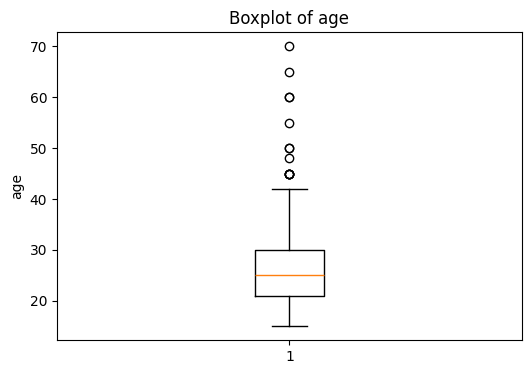

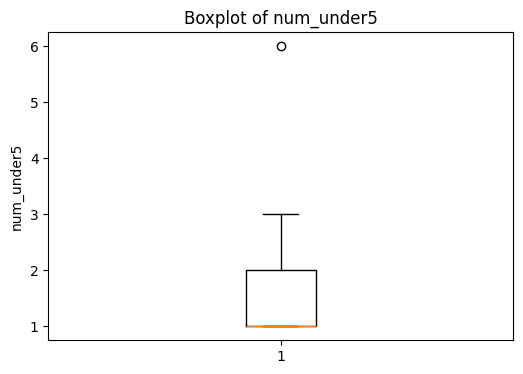

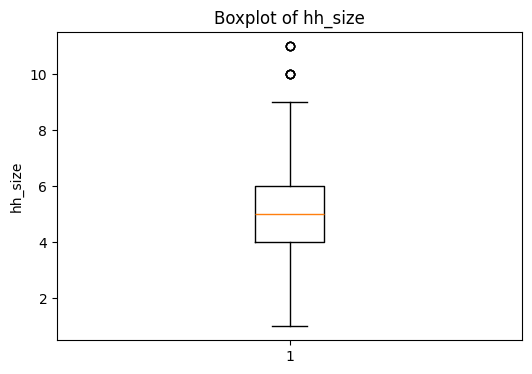

In [ ]:
#Outliers of numerical variables
num_vars = ['age', 'num_under5', 'hh_size']

#Boxplot
import matplotlib.pyplot as plt

for var in num_vars:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[var].dropna())
    plt.title(f'Boxplot of {var}')
    plt.ylabel(var)
    plt.show()


In [ ]:
#Outliers count
for var in num_vars:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[var] < lower) | (df[var] > upper)]

    print(f"{var}: {len(outliers)} outliers")

age: 13 outliers
num_under5: 1 outliers
hh_size: 9 outliers


In [ ]:
#Logical consistency
#under_5Vsnum_under
#if under_5=0, no num_under5
df[(df['under5'] == 0) & (df['num_under5'].notna())][
    ['id', 'under5', 'num_under5']
]
#if diarrhea =0,then skip
post_vars = ['ors', 'treatment', 'duration', 'recovered']

df.loc[df['diarrhea'] == 0, post_vars].notna().sum()


,0
ors,0
treatment,0
duration,0
recovered,0


In [ ]:
#duraton and recoverd only for diarrhea case
df[(df['diarrhea'] == 0) & (df['duration'].notna())]
df[(df['diarrhea'] == 0) & (df['recovered'].notna())]

,id,age,sex,union,village,under5,num_under5,literacy,occupation,hh_size,...,hygiene1,hygiene2,hygiene3,hygiene4,hygiene5,diarrhea,ors,treatment,duration,recovered


# DESCRIPTIVE STATISTICS


NUmerical variable

In [ ]:
#numerical variable ,Distribution check
num_vars = ['age', 'num_under5', 'hh_size']
df[num_vars].describe()


,age,num_under5,hh_size
count,300.000000,300.000000,300.000000
mean,27.083333,1.273333,5.150000
std,8.173887,0.522365,1.771429
min,15.000000,1.000000,1.000000
25%,21.000000,1.000000,4.000000
50%,25.000000,1.000000,5.000000
75%,30.000000,2.000000,6.000000
max,70.000000,6.000000,11.000000


Distribution check(histogram+KDE)-numerical


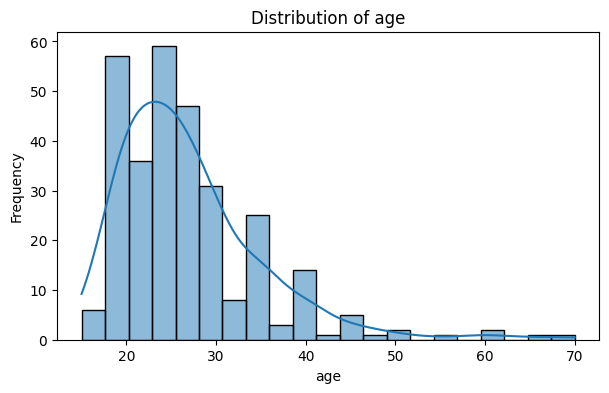

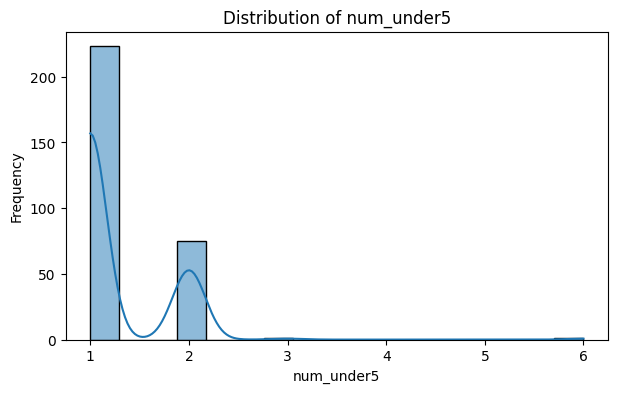

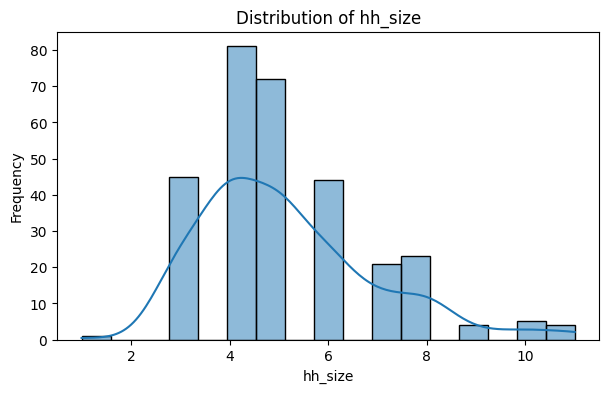

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for var in num_vars:
    plt.figure(figsize=(7,4))
    sns.histplot(df[var].dropna(), kde=True)
    plt.title(f'Distribution of {var}')
    plt.xlabel(var)
    plt.ylabel('Frequency')
    plt.show()

Q_Q plot(numerical)

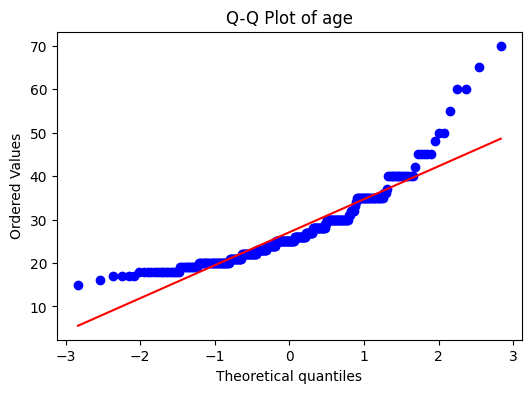

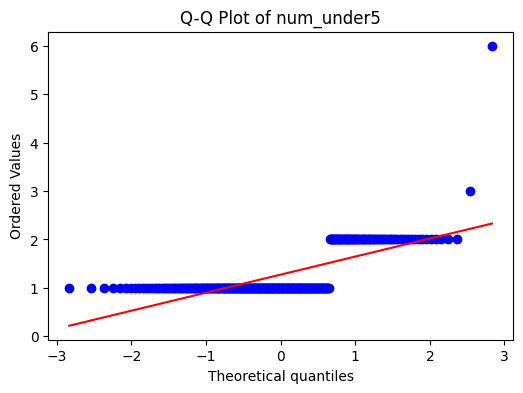

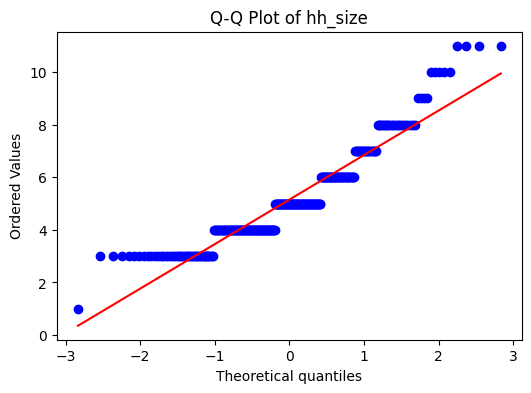

In [ ]:
import scipy.stats as stats

for var in num_vars:
    plt.figure(figsize=(6,4))
    stats.probplot(df[var].dropna(), dist="norm", plot=plt)
    plt.title(f'Q-Q Plot of {var}')
    plt.show()

Normality check using numerical way(shapiro-wilk test)

In [ ]:
for var in num_vars:
    stat, p = stats.shapiro(df[var].dropna())
    print(f"{var}: p-value = {p:.2e}")

age: p-value = 4.41e-16
num_under5: p-value = 4.78e-28
hh_size: p-value = 4.67e-13


Categorical variable (descriptive statistics)

Frequency and percentage

In [ ]:
for var in cat_vars:
    print(f"\n===== {var} =====")

    freq = df[var].value_counts(dropna=False)
    percent = df[var].value_counts(normalize=True, dropna=False) * 100

    result = pd.DataFrame({
        'Frequency': freq,
        'Percentage': percent.round(2)
    })

    display(result)


===== sex =====


,Frequency,Percentage
sex,,
2,290,96.67
1,10,3.33



===== union =====


,Frequency,Percentage
union,,
1,100,33.33
2,100,33.33
3,100,33.33



===== village =====


...

,Frequency,Percentage
treatment,,
NaN,233,77.67
0.0,34,11.33
1.0,33,11.00



===== duration =====


,Frequency,Percentage
duration,,
NaN,234,78.00
1.0,32,10.67
2.0,18,6.00
3.0,16,5.33



===== recovered =====


,Frequency,Percentage
recovered,,
NaN,233,77.67
1.0,53,17.67
0.0,14,4.67


Bar chart

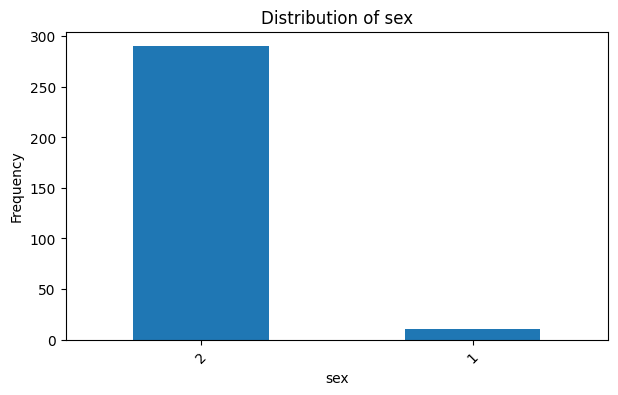

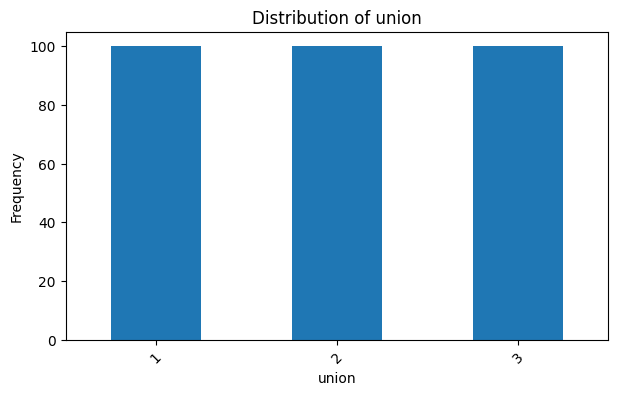

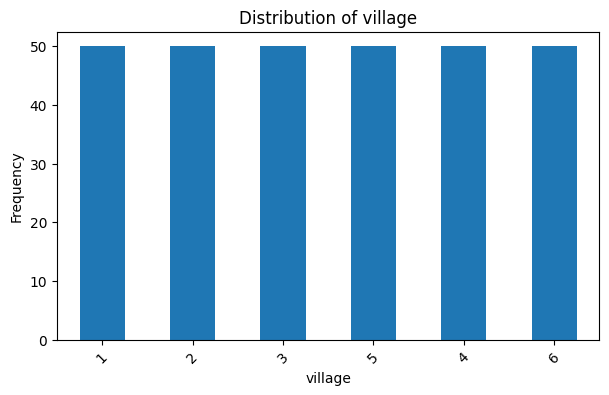

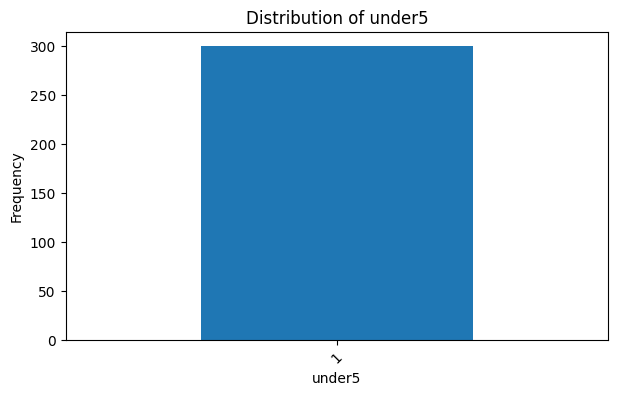

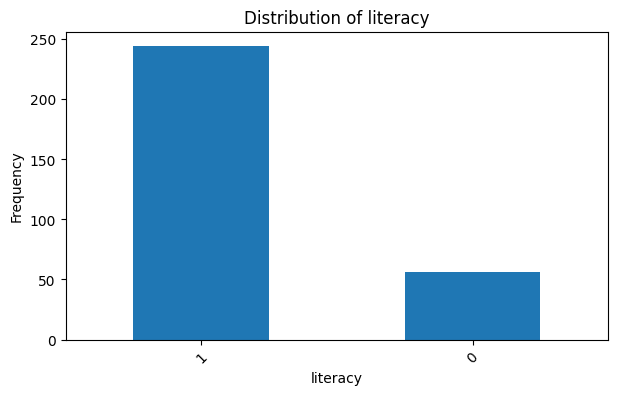

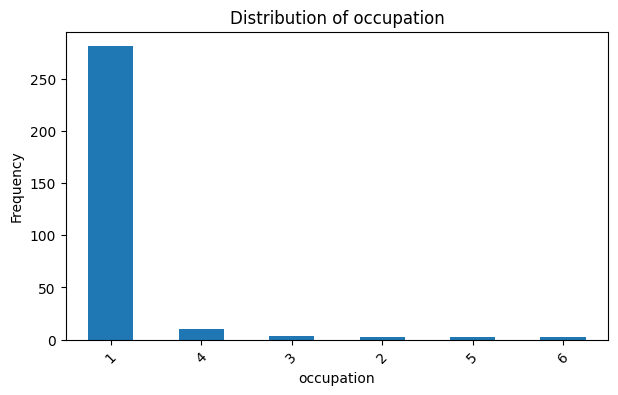

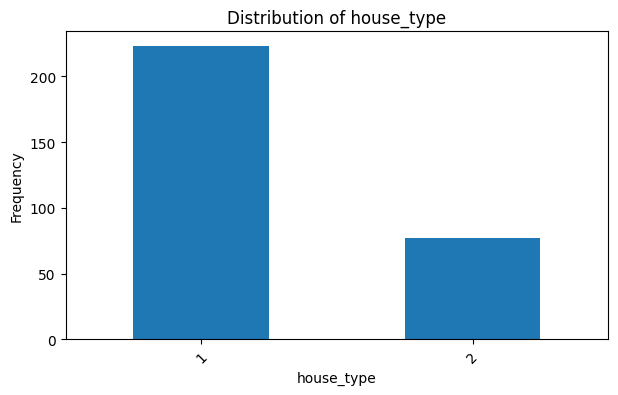

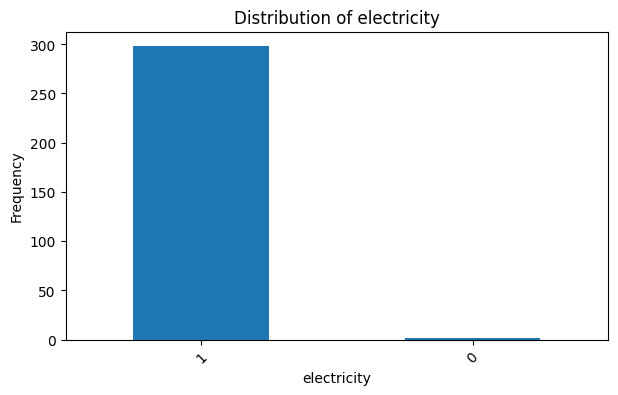

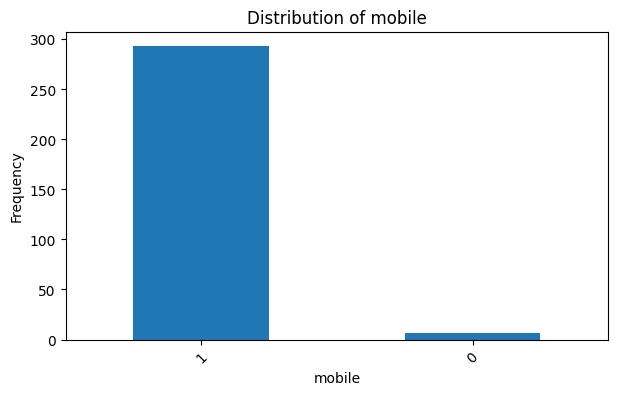

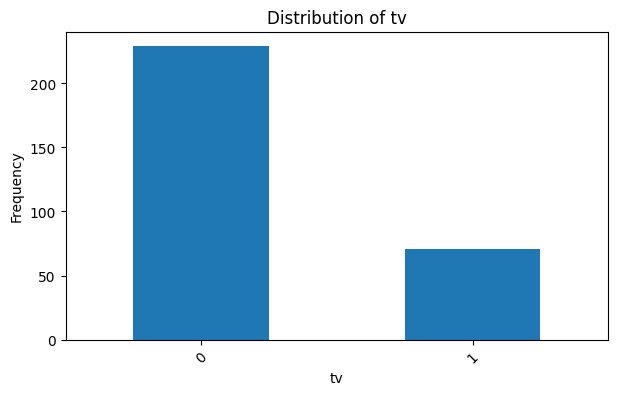

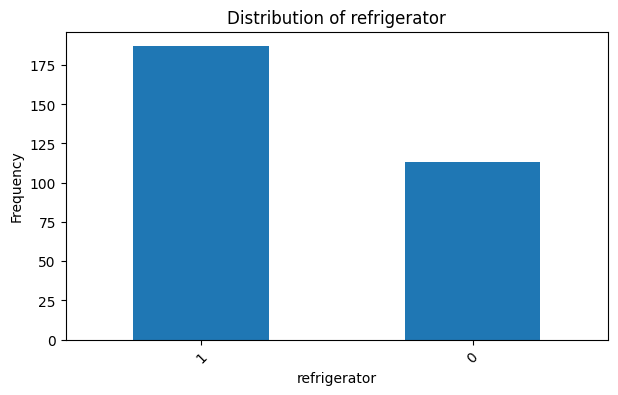

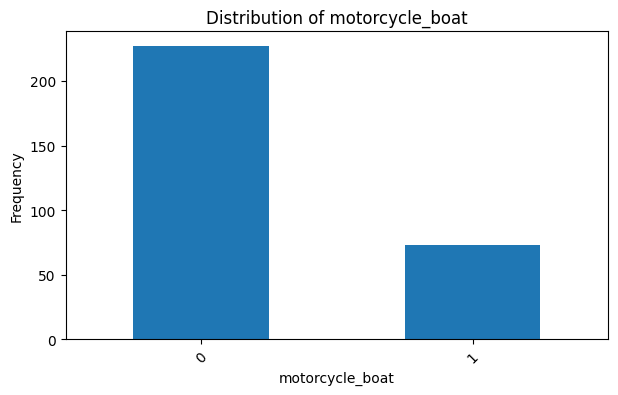

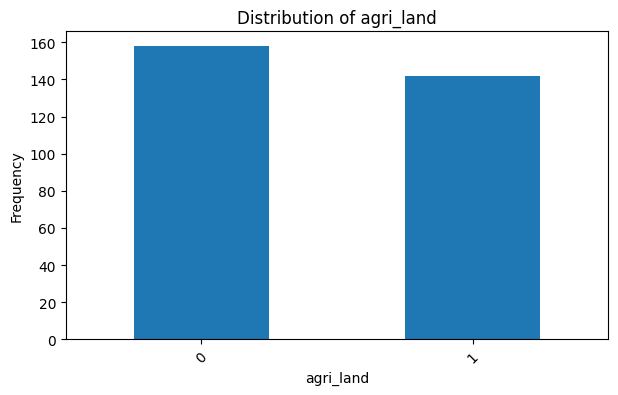

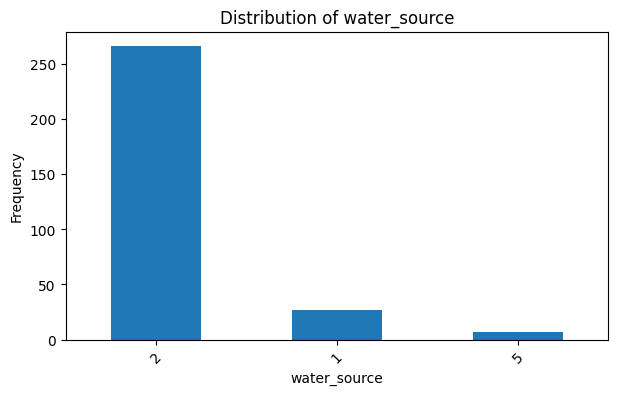

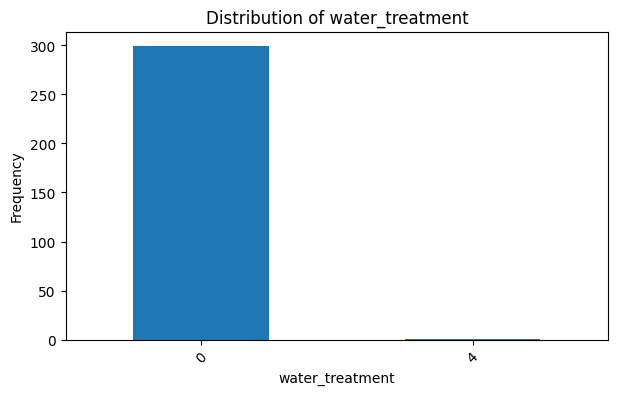

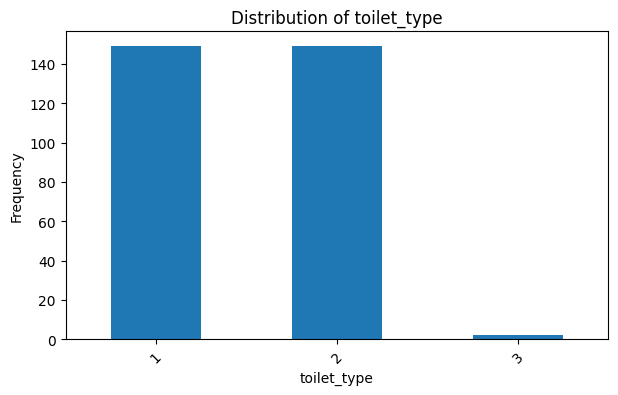

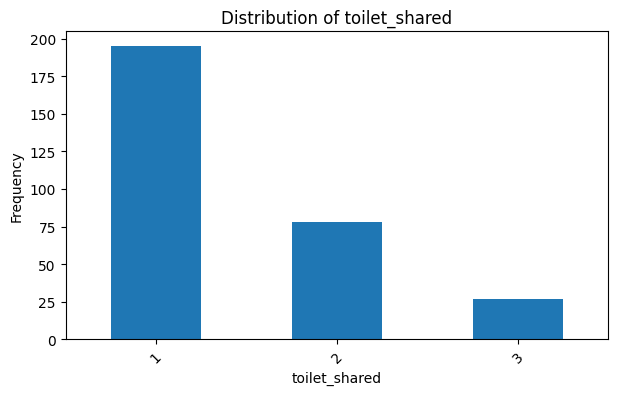

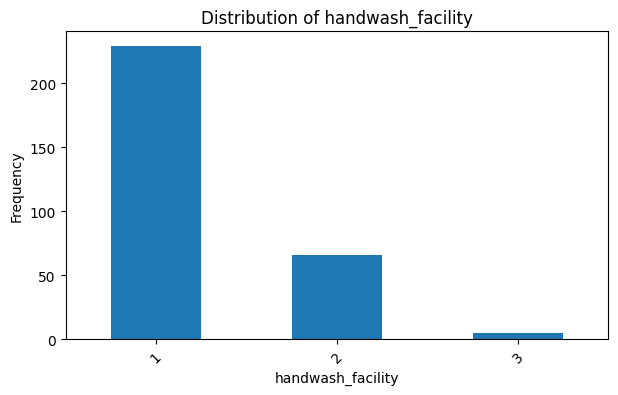

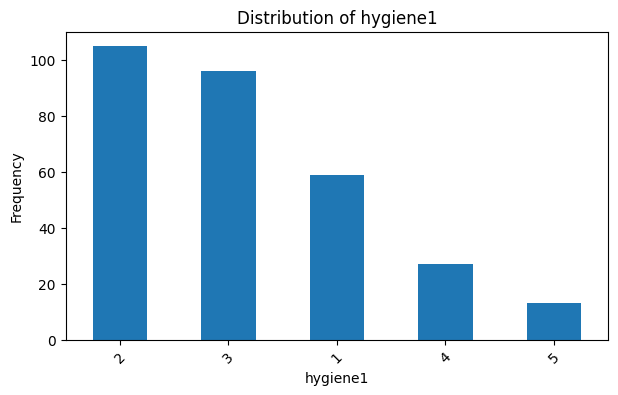

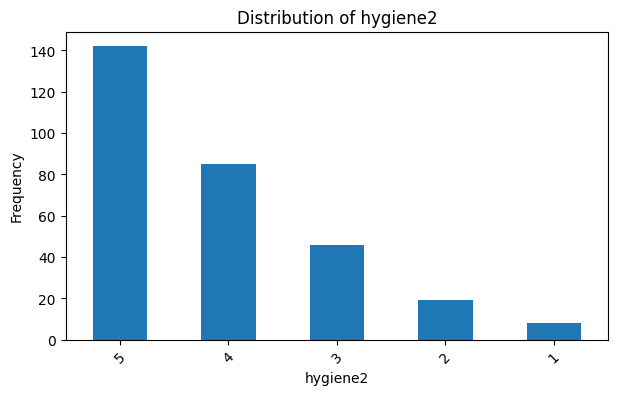

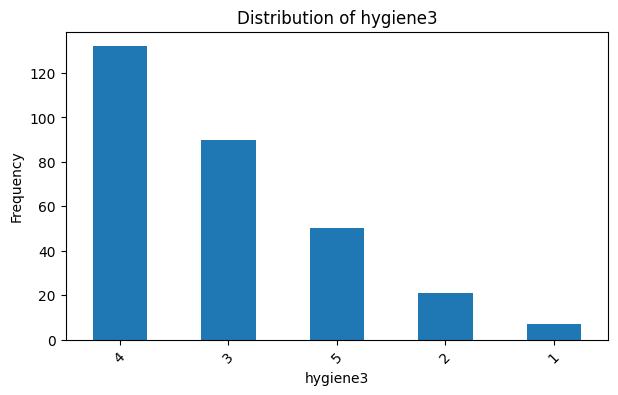

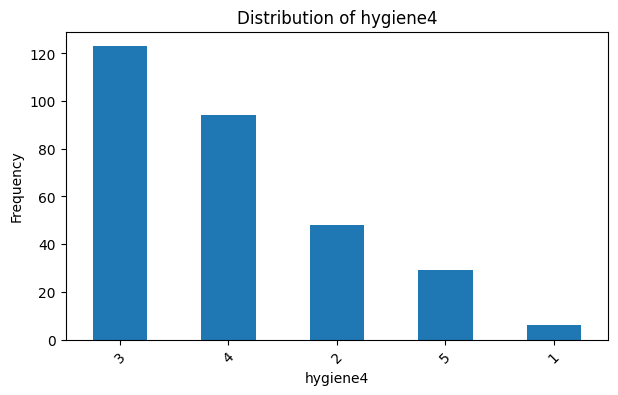

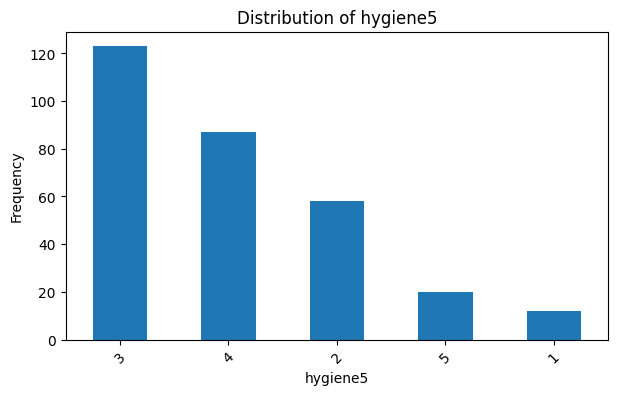

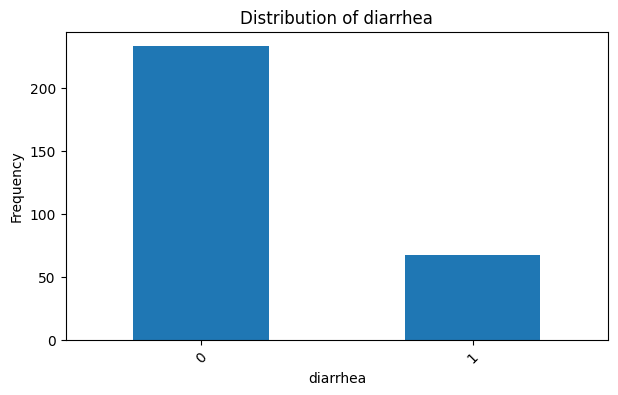

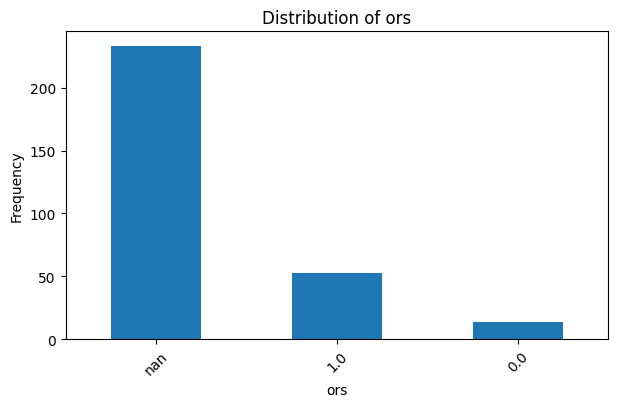

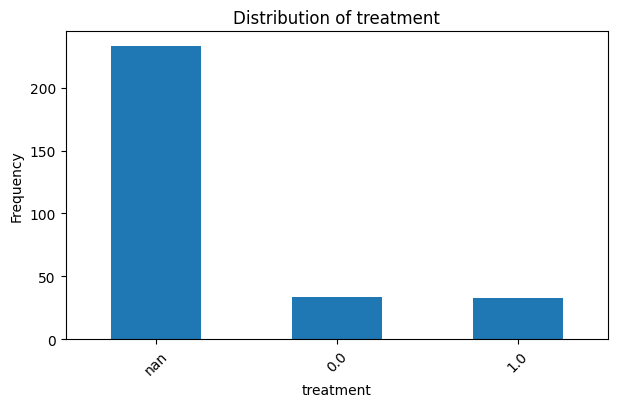

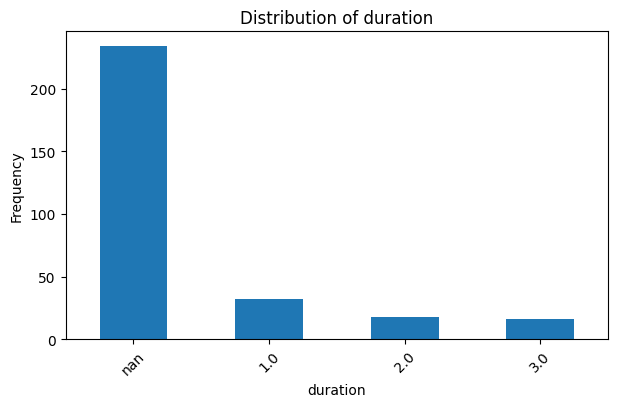

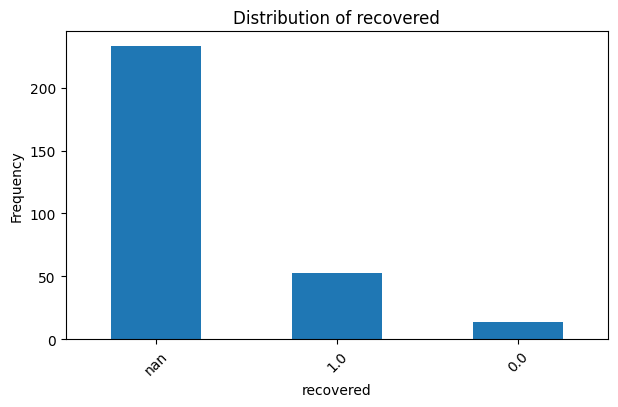

In [ ]:
for var in cat_vars:
    plt.figure(figsize=(7,4))
    df[var].value_counts(dropna=False).plot(kind='bar')
    plt.title(f'Distribution of {var}')
    plt.xlabel(var)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45)
    plt.show()

personal hygine score

In [ ]:
# Hygiene variables
hygiene_vars = ['hygiene1', 'hygiene2', 'hygiene3', 'hygiene4', 'hygiene5']

# Total Hygiene Score
df['hygiene_score'] = df[hygiene_vars].sum(axis=1)

# Hygiene condition category
def hygiene_condition(score):
    if 5 <= score <= 11:
        return 'Poor'
    elif 12 <= score <= 18:
        return 'Moderate'
    elif 19 <= score <= 25:
        return 'Good'
    else:
        return np.nan

df['hygiene_condition'] = df['hygiene_score'].apply(hygiene_condition)

# Check
df[['hygiene1', 'hygiene2', 'hygiene3', 'hygiene4', 'hygiene5',
    'hygiene_score', 'hygiene_condition']].head(20)


  #frequency and percentages
hygiene_summary = pd.DataFrame({
    'Frequency': df['hygiene_condition'].value_counts(),
    'Percentage': df['hygiene_condition']
                    .value_counts(normalize=True)
                    .mul(100)
                    .round(2)
})

hygiene_summary

,Frequency,Percentage
hygiene_condition,,
Moderate,203,67.67
Good,81,27.00
Poor,16,5.33


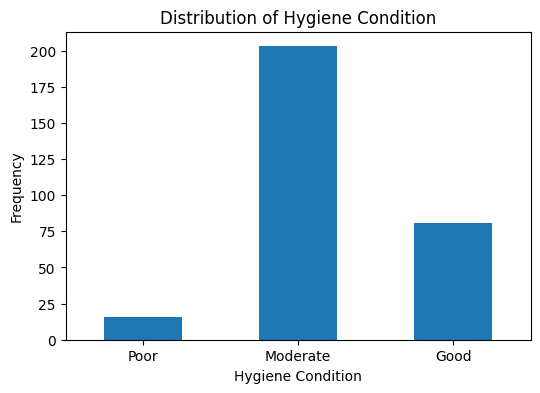

In [ ]:
df['hygiene_condition'].value_counts().reindex(
    ['Poor', 'Moderate', 'Good']
).plot(kind='bar', figsize=(6,4))

plt.xlabel('Hygiene Condition')
plt.ylabel('Frequency')
plt.title('Distribution of Hygiene Condition')
plt.xticks(rotation=0)
plt.show()

# WASH SCORE

# Bivariate Analysis
